## March Madness Simulator


A Data Science Project Created by Chandler Phillips

First make sure to load in all imports:

In [1]:
# Current libraries
import numpy as np
import random 
import matplotlib.pyplot as plt
from matplotlib import colors

# Previously used libraries during earlier development phases
# Retained to document the project's evolution
# import sys
# print(sys.executable)
# import math
# import pandas as pd
# from scipy import stats
# import copy as cp
# print(random.uniform(0,1))

### MMSimCalc — Game Simulation

This algorithm takes two teams and calculates each team's probability of winning based on their seed, points per game (PPG), opponent points per game allowed, and regular-season wins.

The algorithm uses these statistics, along with randomized weights, to calculate each team's win probability. It then simulates a single game and determines which team advances to the next round.

In [2]:
def MMSimCalc(Team1, Team2, show_chart=False, verbose=False):
    Score1=0
    Score2=0
    ###Rank:
    Score1=Score1 + (17-Team1["seed"])
    Score2=Score2 + (17-Team2["seed"])
    PPG1=Team1["ppg"]
    PPG2=Team2["ppg"]
    ####PPG
    if(PPG1>PPG2):
        HoldDiff=PPG1-PPG2
        if HoldDiff>9:
            HoldDiff=9
        randomMult=.50+random.uniform(0,.75)
        Score1=Score1+(randomMult*HoldDiff)
        #print(randomMult*HoldDiff)

    if(PPG1<PPG2):
        HoldDiff=PPG2-PPG1
        if HoldDiff>9:
            HoldDiff=9
        randomMult=.50+random.uniform(0,.75)
        Score2=Score2+(randomMult*HoldDiff)
        #print(randomMult)
        
    #####OPP PPG
    OPP1=Team1["opp_ppg"]
    OPP2=Team2["opp_ppg"]
    if(OPP1>OPP2):
        ####ADD to other score
        HoldDiff=abs(OPP2-OPP1)
        if HoldDiff>9:
            HoldDiff=9
        randomMult=.50+random.uniform(0,.75)
        Score2=Score2+(randomMult*HoldDiff)
        #print(randomMult*HoldDiff)

    if(OPP1<OPP2):
        ####ADD to other score
        HoldDiff=abs(OPP1-OPP2)
        if HoldDiff>9:
            HoldDiff=9
        randomMult=.50+random.uniform(0,.75)
        Score1=Score1+(randomMult*HoldDiff)
        #print(randomMult*HoldDiff)

    ###Wins
    WIN1=Team1["wins"]
    WIN2=Team2["wins"]
    if(WIN1==WIN2):
        Holder1=2+random.uniform(0,3)
        Holder2=2+random.uniform(0,3)
        Score1=Score1+ Holder1
        Score2=Score2+ Holder2
    if(WIN1>WIN2):
        HoldDiff=abs(WIN1-WIN2)
        if HoldDiff>5:
            HoldDiff=5
        randomMult=.80+random.uniform(0,.4)
        Score1=Score1+(randomMult*HoldDiff)
    if(WIN2>WIN1):
        HoldDiff=abs(WIN2-WIN1)
        if HoldDiff>5:
            HoldDiff=5
        randomMult=.80+random.uniform(0,.4)
        Score2=Score2+(randomMult*HoldDiff)
    
    PointsTotal = Score1 + Score2
    if PointsTotal == 0:
        Prob = 0.5
    else:
        Prob = Score1 / PointsTotal
    #print(Prob)
    if show_chart:
        fig = plt.figure(figsize = (5, 5))
        
        xlist=(Team1["name"],Team2["name"],"total prob")
        ylist=(Prob,1-Prob,1)
        # creating the bar plot
        plt.bar(xlist,ylist, color ='green',
                width = .2,)
        plt.xlabel("Teams")
        plt.ylabel("From Bottom is prob for first team")
        plt.title("GAME PROB")
        plt.show()
     # Simulate one game using the calculated probabilities
    winner_index = np.random.choice([0, 1], p=[Prob, 1 - Prob])
    # Determine the winning team
    winner = Team1 if winner_index == 0 else Team2
    # Print the winner only when requested
    if verbose:
        print(f"#{winner['seed']} {winner['name']} moves on!")
    return winner



## 2022 (Archived Data)

In [3]:
# ## Team Name, Rank, Average points per game,Average OPP points per game, wins per season, losses per season
#2022 SEASON
# # West
# Team1=["Gonzaga",1,87.8,65.3,26,3]
# Team2=["Georgie State",16,70.6,70.6,18,10]
# Team3=["Boise State",8,68.7,60.8,27,7]
# Team4=["Memphis",9,75.4,68.4,21,10]
# Team5=["UConn",5,75.2,65.2,23,9]
# Team6=["New Mexico State",12,73.3,65.0,26,6]
# Team7=["Arkansas", 4,76.9,68.5,25,8]
# Team8=["Vermont",13,74.9,60.3,28,5]
# Team9=["Alabama", 6,80.0,76.4,19,13]
# Team10=["Rutg/ND",11,0,0,0,0]##Finish
# Team11=["Texas Tech",3, 71.7, 60.3,25,9]
# Team12=["Montana State", 14,77.0,68.5,27,7]
# Team13=["Michigan State",7,72.1,68.4,22,12]
# Team14=["Davidson",10,75.6,65.8,27,6]
# Team15=["Duke", 2,80.2,67.1,28,6]
# Team16=["CSU Fullerton", 15,70.3,66.2,21,10]

# # East
# Team17=["Baylor",1,76.5,63.6,26,6]
# Team18=["Norfolk",16,75.1,63.7,24,6]
# Team19=["North Carolina",8,77.5,71.7,24,9]
# Team20=["Marquett",9,74.4,70.9,19,12]
# Team21=["Saint Mary's",5,69.8,60.5,25,7]
# Team22=["Wyo",12,0,0,0,0] #########FINISH
# Team23=["UCLA",4,76.4,64.8,25,7]
# Team24=["Akron",13,71.2,62.8,24,9]
# Team25=["Texas",6,68.3,59.6,21,11]
# Team26=["Virgina Tech",11,70.7,62.3,23,12]
# Team27=["Purdue",3,79.8,68.8,27,7]
# Team28=["Yale",14,72.3,68.8,19,11]
# Team29=["Murray State",7,79.3,62.3,30,2]
# Team30=["San Franscico",10,77.1,67.0,24,9]
# Team31=["Kentucky",2,79.5,66.0,26,7]
# Team32=["Saint Peter's",15,66.9,61.8,19,11]

# # South
# Team33=["Arizona",1,84.6,67.5,31,3]
# Team34=["WRST/BRY",16,0,0,0,0]###############FINISH
# Team35=["Seton Hall",8,72.9,66.3,21,10]
# Team36=["TCU",9,68.1,65.0,20,12]
# Team37=["Houston",5,75.8,58.9,29,5]
# Team38=["UAB",12,80.7,66.3,27,7]
# Team39=["Illinois",4,75.8,67.6,22,9]
# Team40=["Chattanooga",13,74.8,64.7,27,7]
# Team41=["CSU",6,73.7,65.7,25,5]
# Team42=["Michigian",11,73.0,69.9,17,14]
# Team43=["Tennessee",3,73.2,62.8,26,7]
# Team44=["LongWood",14,76.3,65.1,26,6]
# Team45=["Ohio State",7,73.8,68.5,19,11]
# Team46=["Loyola Chicago",10,73.8,61.7,25,7]
# Team47=["Villanova",2,72.6,63.1,26,7]
# Team48=["Delaware",15,73.8,69.9,22,12]

# #MidWest
# Team49=["Kansas",1,78.6,68.1,28,6]
# Team50=["TXSO",16,69.2,65.5,18,12]
# Team51=["San diego state",8,65.3,57.7,23,8]
# Team52=["creighton",9,69.0,65.9,22,11]
# Team53=["Iowa",5,83.8,71.3,26,9]
# Team54=["Richmond",12,71.7,68.3,23,12]
# Team55=["Providence",4,71.8,67.0,25,5]
# Team56=["S Dakota state",13,86.7,73.4,30,4]
# Team57=["LSU",6,73.1,63.5,22,11]
# Team58=["Iowa State",11,66.5,63.0,20,12]
# Team59=["Wisconsin",3,70.1,66.5,24,7]
# Team60=["colgate",14,76.1,67.1,23,11]
# Team61=["USC",7,72.6,65.9,26,7]
# Team62=["Miami",10,74.8,71.0,23,10]
# Team63=["Auburn",2,78.7,67.0,27,5]
# Team64=["J'Ville State",15,73.9,66.8,21,10]

## 2023 (Archived Data)

In [4]:
# # 2023 (archived Data)
# Team Name, Rank, Average points per game,Average OPP points per game, wins per season

# ###2023: NOTE TEAMS GO IN ORDER EVEN OFF BRACKET so 
# # South
# Team1=["ALABAMA",1,82.2,68.5,29]# 1 seed
# Team2=["Texas A&M-CC",16,80.4,72.5,23] #16 seed etc
# Team3=["MaryLand",8,70.4,63.2,21]
# Team4=["West Virginia",9,76.3,71.0,19]
# Team5=["San Diego State",5,72.1,63.6,27]
# Team6=["Charleston",12,80.8,67.4,31]
# Team7=["Virginia", 4,67.8,60.3,25]
# Team8=["Furman",13,71.2,82.1,27]
# Team9=["Creigton", 6,76.6,68.5,21]
# Team10=["NC State",11,78.2,70.8,23]
# Team11=["Baylor",3, 77.2, 70.3,22]
# Team12=["UCSB", 14,72.2,65.5,27]
# Team13=["Missouri",7,79.5,74.6,24]
# Team14=["Utah State",10,69.7,69.7,26]
# Team15=["Arizona", 2,82.7,71.5,28]
# Team16=["Princeton", 15,76.0,68.8,21]

# # East
# Team17=["Purdue",1,73.1,62.7,29]
# Team18=["TXSO/FDU",0,0,0,0]#########FINISH
# Team19=["Memphis",8,79.8,71.9,26]
# Team20=["FAU",9,78.8,65.0,31]
# Team21=["DUKE",5,72.5,63.9,26]
# Team22=["Oral Roberts",12,84.2,70.1,30] 
# Team23=["Tennessee",4,71.8,58.0,23]
# Team24=["Lousiana",13,78.0,69.8,26]
# Team25=["Kentucky",6,75.1,68.0,21]
# Team26=["Providence",11,78.1,71.3,21]
# Team27=["Kansas State",3,75.5,69.0,23]
# Team28=["Montana State",14,74.2,66.6,25]
# Team29=["Michigan State",7,70.2,67.4,19]
# Team30=["USC",10,72.8,67.3,22]
# Team31=["Marquette",2,79.9,70.6,28]
# Team32=["Vermont",15,73.0,66.6,23]

# # Midwest
# Team33=["Houston",1,75.0,56.5,31]
# Team34=["North Kentucky",16,68.2,63.6,22]
# Team35=["Iowa",8,80.2,74.4,19]
# Team36=["Auburn",9,72.7,67.1,20]
# Team37=["Miami",5,79.4,72.1,25]
# Team38=["Drake",12,75.3,63.9,27]
# Team39=["Indiana",4,75.0,68.5,22]
# Team40=["Kent State",13,76.6,65.7,28]
# Team41=["Iowa State",6,68.4,62.8,19]
# Team42=["Pittsburg",11,76.1,70.5,22]
# Team43=["Xavier",3,81.4,74.1,25]
# Team44=["Kennesaw st",14,75.3,68.9,26]
# Team45=["Texas A&M",7,73.2,66.2,25]
# Team46=["Penn State",10,72.3,68.4,22]
# Team47=["Texas",2,77.9,67.4,26]
# Team48=["Colgate",15,78.6,69.0,26]

# #west
# Team49=["Kansas",1,74.9,67.9,27]
# Team50=["Howard",16,75.5,71.9,22]
# Team51=["Arkansas",8,74.4,67.4,20]
# Team52=["Illinois",9,74.7,67.0,20]
# Team53=["Saint Mary's",5,71.4,60.1,26]
# Team54=["VCU",12,71.4,62.9,27]
# Team55=["UCONN",4,78.5,65.0,25]
# Team56=["Iona",13,76.4,65.0,27]
# Team57=["TCU",6,75.2,67.9,21]
# Team58=["ASU/NEV",11,0,0,0]#########
# Team59=["Gonzaga",3,87.5,72.9,28]
# Team60=["Grand Canyon",14,75.3,66.8,24]
# Team61=["NorthWestern",7,67.7,62.5,21]
# Team62=["Boise State",10,72.2,64.3,24]
# Team63=["UCLA",2,73.9,60.3,29]
# Team64=["UNC Asheville",15,75.0,86.6,27]

## 2024 (Archived Data)

In [5]:
# ## Team Name, Rank, Average points per game,Average OPP points per game, wins per season

# ###2024: NOTE TEAMS GO IN ORDER EVEN OFF BRACKET so 
# # EAST
# Team1=["UCONN",1,81.5,64.4,31]# 1 seed
# Team2=["Stetson",16,77.5,72.8,22] #16 seed etc
# Team3=["FAU",8,82.5,73.3,25]
# Team4=["North Western",9,73.7,68.0,21]
# Team5=["San Diego State",5,74.6,66.6,24]
# Team6=["UAB",12,77.8,75.2,23]
# Team7=["Auburn", 4,83.3,68.0,27]
# Team8=["Yale",13,75.2,66.6,22]
# Team9=["BYU", 6,81.8,69.9,23]
# Team10=["Duquesne",11,70.8,66.0,24]
# Team11=["Illinois",3, 84.4,73.8,26]
# Team12=["Morehead", 14,75.5,62.8,26]
# Team13=["Washington State",7,74.3,66.9,24]
# Team14=["Drake",10,80.5,70.5,28]
# Team15=["Iowa State", 2,75.6,61.3,27]
# Team16=["S Dakota state", 15,76.8,70.8,22]

# # WEST
# Team17=["North Carolina",1,81.5,70.2,27]
# Team18=["WAGNER",16,63.8,62.3,17]#########FINISH
# Team19=["Mississippi State",8,74.8,69.1,21]
# Team20=["Michigan state",9,73.1, 65.9,19]
# Team21=["Saint Marys",5,74.2,58.7,26]
# Team22=["GCU",12,79.8,66.9,29] 
# Team23=["Alabama",4,90.8,81.1,21]
# Team24=["Charleston",13,80.5,72.5,27]
# Team25=["Clemson",6,77.4,71.3,21]
# Team26=["New Mexico State",11,81.4,70.5,26]
# Team27=["Baylor",3,80.5,71.2,23]
# Team28=["Colgate",14,71.5,63.2,25]
# Team29=["Dayton",7,74.7,66.3,24]
# Team30=["Nevada",10,76.4,67.1,26]
# Team31=["Arizona",2,87.9, 72.2, 25]
# Team32=["Long Beach St",15,77.7,75.7,21]

# # South
# Team33=["Houston",1,73.0,57.0,30]
# Team34=["Long Wood",16,75.6,676.9,21]###############FINISH
# Team35=["Nebraska",8,77.6,70.1,23]
# Team36=["Texas A&M",9,74.8,70.8,20]
# Team37=["Wisconsin",5,75.1,69.9,22]
# Team38=["James Madison",12,84.4,69.2,31]
# Team39=["Duke",4,79.8,67.4,24]
# Team40=["Vermont",13,72.3,63.0,28]
# Team41=["Texas Tech",6,75.6,69.3,23]
# Team42=["NC state",11,76.4,72.7,22]
# Team43=["Kentucky",3,89.4,79.7,23]
# Team44=["Oakland",14,76.4,72.9,23]
# Team45=["Florida",7,85.1,78.5,24]
# Team46=["CU SKOOOOOOOO",10,79.3,71.2,25]
# Team47=["Marquette",2,78.3,69.7,25]
# Team48=["Western KY",15,80.6,74.1,22]

# #Midwest
# Team49=["Purdue",1,83.4,70.2,29]
# Team50=["Grambling",16,67.6,69.0,21]
# Team51=["Utah State",8,79.8,70.3,27]
# Team52=["TCU",9,79.2,71.2,21]
# Team53=["Gonzaga",5,84.9,69.0,25]
# Team54=["Mcneese",12,80.4,61.5,30]
# Team55=["Kansas",4,75.2,68.7,22]
# Team56=["Samford",13,86.0,73.9,29]
# Team57=["South Carolina",6,72.0,67.0,26]
# Team58=["oregon",11,75.3,71.9,23]#########
# Team59=["Creighton",3,80.5,69.7,23]
# Team60=["Akron",14,74.0,65.9,24]
# Team61=["Texas",7,76.5,69.9,20]
# Team62=["Colorado State",10,69.9,67.6,25]
# Team63=["Tennessee",2,79.5,67.9,24]
# Team64=["St. Peters",15,65.3,63.4,19]

## 2025 Data (Current Simulation)

In [6]:
## Team Name, Rank, Average points per game,Average OPP points per game, wins per season

###2025: NOTE TEAMS GO IN ORDER EVEN OFF BRACKET so 
# SOUTH
Team1=["Auburn",1,83.8,69.6,28]# 1 seed
Team2=["Alabama St",16,73.3,72.1,20] #16 seed etc
Team3=["Louisville",8,78.6,68.9,27]
Team4=["Creighton",9,75.2,69.5,24]
Team5=["Michigan",5,78.3,71.2,25]
Team6=["UC San Diego",12,79.8,61.6,30]
Team7=["Texas A&M",4,74.3,67.9,22]
Team8=["Yale",13,81.7,69.7,22]
Team9=["Ole Miss",6,77.2,71.7,22]
Team10=["North Carolina",11,81.2,74.8,23]
Team11=["Iowa State",3,80.4,68.1,24]
Team12=["Lipscomb",14,79.3,67.3,25]
Team13=["Marquette",7,76.9,68.5,23]
Team14=["New Mexico",10,81.2,70.8,26]
Team15=["Michigan State", 2,78.2,67.2,27]
Team16=["Bryant",15,81.7,74.2,23]

# WEST
Team17=["Florida",1,85.4,69.2,30]
Team18=["Norfolk st",16,77.3,69.0,24]
Team19=["UConn",8,77.4,68.0,23]
Team20=["Oklahoma",9,78.8,74.8,20]
Team21=["Memphis",5,80.1,73.2,29]
Team22=["CSU",12,75.2,67.1,25] 
Team23=["Maryland",4,81.7,67.0,25]
Team24=["Grand Canyon",13,79.2,69.1,26]
Team25=["Missouri",6,84.5,73.8,22]
Team26=["Drake",11,70.1,58.4,30]
Team27=["Texas Tech",3,80.9,67.6,25]
Team28=["UNC Wilmington",14,79.4,69.9,27]
Team29=["Kansas",7,76.2,69.3,21]
Team30=["Arkansas",10,76.6,71.2,20]
Team31=["St. Johns",2,78.7,65.9,30]
Team32=["Omaha",15,78.1,75.0,22]

# EAST
Team33=["Duke",1,82.7,61.9,31]
Team34=["MSM",16,68.1, 70.1, 23]######FINISH
Team35=["Mississippi St",8,79.8,74.2,21]
Team36=["Baylor",9,76.5,69.2,19]
Team37=["Oregon",5,76.2,70.9,24]
Team38=["Liberty",12,76.6,62.9,28]
Team39=["Arizona",4,81.7,72.4,22]
Team40=["Akron",13,84.6,74.5,28]
Team41=["BYU",6,81.0,71.1,24]
Team42=["VCU",11,77.1,62.4,28]
Team43=["Wisconsin",3,79.7,70.4,26]
Team44=["Montana",14,76.9,72.9,25]
Team45=["Saint Mary's",7,73.5,60.7,28]
Team46=["Vanderbilt",10,79.6,74.8,20]
Team47=["Alabama",2,91.1,81.4,25]
Team48=["Robert Morris",15,76.9,70.4,26]

#Midwest
Team49=["Houston",1,74.2,58.5,30]
Team50=["SIUE",16,72.6,66.1,22]
Team51=["Gonzaga",8,86.6,69.6,25]
Team52=["Georgia",9,75.6,69.3,20]
Team53=["Clemson",5,76.3,65.7,27]
Team54=["Mcneese",12,77.2,64.0,27]
Team55=["Purdue",4,77.9,71.1,22]
Team56=["High Point",13,82.2,68.8,29]
Team57=["Illinois",6,83.8,74.6,21]
Team58=["Xav",11, 70.0, 75.1, 20] 
Team59=["Kentucky",3,85.3,77.9,22]
Team60=["Troy",14,73.9,65.4,23]
Team61=["UCLA",7,74.8,65.7,22]
Team62=["Utah State",10,80.9,70.0,26]
Team63=["Tennessee",2,74.7,63.0,27]
Team64=["Wofford",15,75.3,69.8,19]

**No Data for 2026**

## Organizing Team Data Using Dictionaries

Originally, each team's statistics were stored in a list and accessed using numerical indices. To improve readability and make the code easier to maintain, I converted each team's data into a dictionary with descriptive keys.

Using dictionaries allows us to reference statistics by name, such as team["ppg"] instead of team[2]. This makes the code easier to understand, reduces confusion when accessing team statistics, and allows me to add new statistics in the future without relying on fixed index positions.

The teams are also kept in a list to preserve their original tournament bracket order.

In [7]:
# CONVERT THEM INTO A DICTIONARY: Better readability & easier to use
# Step 1: Collect all 64 teams in bracket order
original_teams = [globals()[f"Team{i}"] for i in range(1, 65)]

# Step 2: Convert each team into a dictionary
teams = [
    {
        "name": team[0],
        "seed": team[1],
        "ppg": team[2],
        "opp_ppg": team[3],
        "wins": team[4]
    }
    for team in original_teams
]

In [ ]:
# Test Case to make verify first seed data and number of teams stored in dictionary
print(teams[0])
print(teams[0]["name"])
print(teams[0]["ppg"])
print(len(teams))

{'name': 'Auburn', 'seed': 1, 'ppg': 83.8, 'opp_ppg': 69.6, 'wins': 28}
Auburn
83.8
64


Let's double check to make sure all data loaded into dictionary correctly:

In [9]:
# Check that all 64 teams are present
if len(teams) != 64:
    print(f"Warning: Expected 64 teams, found {len(teams)}")
# Required dictionary keys
required_keys = ["name", "seed", "ppg", "opp_ppg", "wins"]
# Validate each team
for team in teams:
    # Check for missing keys
    missing_keys = [
        key for key in required_keys
        if key not in team
    ]
    if missing_keys:
        print(f"Missing keys in {team.get('name', 'Unknown')}: {missing_keys}")
        continue
    # Check for invalid statistics
    if not 1 <= team["seed"] <= 16:
        print(f"Invalid seed: {team['name']}")
    if team["ppg"] <= 0:
        print(f"Invalid PPG: {team['name']}")
    if team["opp_ppg"] <= 0:
        print(f"Invalid opponent PPG: {team['name']}")
    if team["wins"] <= 0:
        print(f"Invalid wins: {team['name']}")

print("Check Completed")

Check Completed


### Test case for MMSimCalc:

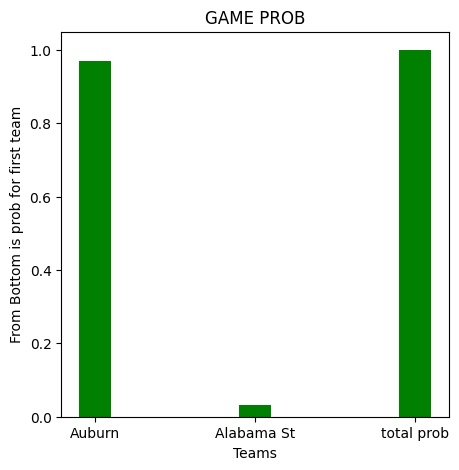

#1 Auburn moves on!
Auburn


In [10]:
winner = MMSimCalc(teams[0], teams[1],show_chart=True ,verbose=True) # Change show_chart to see probability graph
print(winner["name"])

# Run Bracket: 

This section handles the tournament bracket by simulating each round and advancing the winning teams until a national champion is determined.


## simulate_round()

This function takes the remaining teams in the bracket and pairs them up to compete against each other. It uses MMSimCalc() to simulate each matchup and returns a list of the winning teams that advance to the next round.

In [11]:

def simulate_round(remaining_teams, show_chart=False,verbose=False):
    winners = []

    for i in range(0, len(remaining_teams), 2):
        team1 = remaining_teams[i]
        team2 = remaining_teams[i + 1]

        winner = MMSimCalc(team1, team2, show_chart=show_chart, verbose=verbose)
        winners.append(winner)

    return winners


## simulate_tournament()

This function runs the entire March Madness tournament, starting with 64 teams. It repeatedly calls simulate_round(), eliminating half the remaining teams each round until only one team remains. That team is returned as the national champion.

In [12]:

def simulate_tournament(teams):
    remaining_teams = teams.copy()
    # Run until theres only one winner
    while len(remaining_teams) > 1:
        remaining_teams = simulate_round(remaining_teams,show_chart=False, verbose=False)

    return remaining_teams[0]

In [13]:
#Test Case:

#simulate_tournament(teams)

## Running 1,000 Tournament Simulations

Now let's run the March Madness tournament 1,000 times to see how often each team wins the national championship!

Each simulation starts with 64 teams and runs through all six rounds until one champion remains. We use a dictionary to track how many championships each team wins across all 1,000 simulations.

Once the simulations are complete, we calculate each team's estimated championship probability by dividing their total championship wins by the number of simulations. Finally, we rank the teams from highest to lowest championship probability to see which teams our algorithm predicts have the best chance of winning it all.

In [14]:
random.seed(25)
np.random.seed(25)
num_simulations = 1000
# Dictionary to track championships won by each team
championship_counts = {
    team["name"]: 0 for team in teams
}

# Run 1,000 complete tournaments
for i in range(num_simulations):
    champion = simulate_tournament(teams)
    championship_counts[champion["name"]] += 1
print("Completed", num_simulations, "simulations!")

championship_probabilities = {}
for team, wins in championship_counts.items():
    probability = (wins / num_simulations) * 100
    championship_probabilities[team] = probability

ranked_teams = sorted(
    championship_probabilities.items(),
    key=lambda team: team[1],
    reverse=True
)

print("TOP 10 CHAMPIONSHIP CONTENDERS:")

for rank, (team, probability) in enumerate(ranked_teams[:10], start=1):
    print(f"{rank}. {team}: {probability:.2f}%")


Completed 1000 simulations!
TOP 10 CHAMPIONSHIP CONTENDERS:
1. Duke: 17.00%
2. Florida: 10.80%
3. St. Johns: 9.10%
4. Auburn: 8.80%
5. Houston: 7.80%
6. Tennessee: 3.70%
7. Michigan State: 3.50%
8. Maryland: 3.10%
9. UC San Diego: 3.00%
10. Iowa State: 3.00%


In [15]:
### Lets double check and make sure the simulation is valid and we are getting correct values

assert sum(championship_counts.values()) == num_simulations

assert abs(
    sum(championship_probabilities.values()) - 100
) < 1e-9

print("Simulation results validated!")

Simulation results validated!


## Visualizing Championship Probabilities

Now that we've completed 1,000 tournament simulations, let's visualize the results:

The bar chart below displays the 10 teams with the highest estimated championship probabilities based on our simulation results. This makes it easier to compare the top contenders and see which teams our algorithm favors to win the national championship.

**Note:** These percentages are estimates generated by the simulation model, not guaranteed predictions of real tournament outcomes.

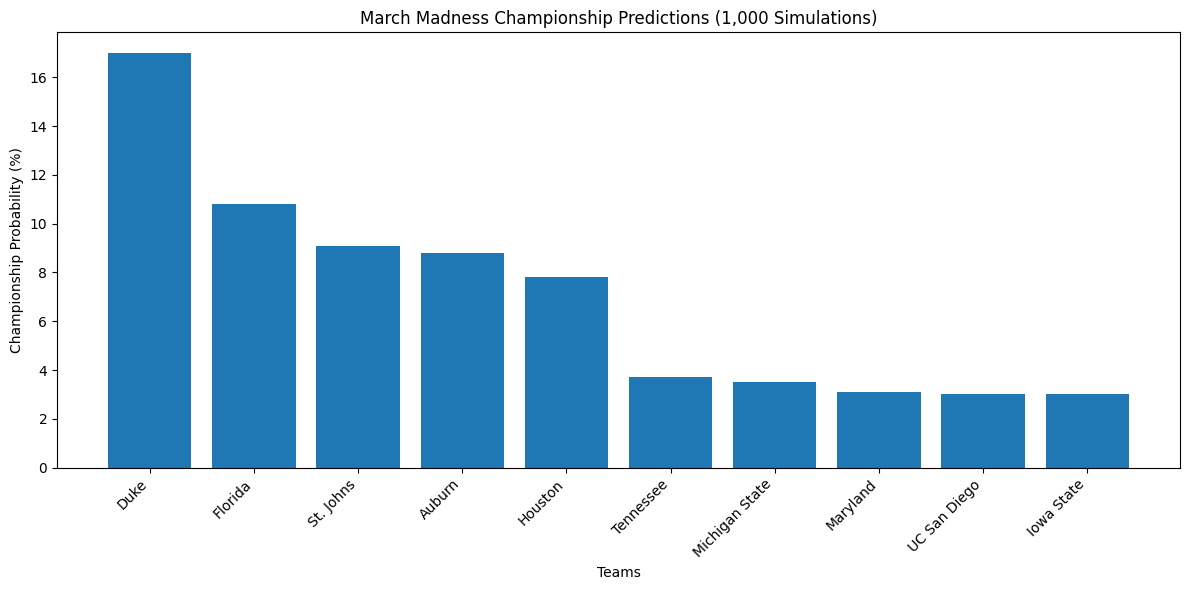

In [16]:
top_10 = ranked_teams[:10]

team_names = [team[0] for team in top_10]
probabilities = [team[1] for team in top_10]

plt.figure(figsize=(12, 6))

plt.bar(team_names, probabilities)

plt.xlabel("Teams")
plt.ylabel("Championship Probability (%)")
plt.title("March Madness Championship Predictions (1,000 Simulations)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()